# Exploratory Data Analysis: UCI Heart Disease (Cleveland)

**Data:** 303 patients, 13 features, binary target `heart_disease` (0 = no, 1 = yes).
Produced by `src/download_data.py` then `src/clean_data.py`.

**Goal:** understand the data before modelling: missing values, class balance,
which features separate sick from healthy patients. Every chart is also saved to
`report/figures/` for the final report.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent                 # notebook is in notebooks/, project root is one level up
FIG_DIR = ROOT / "report" / "figures"    # charts are saved here for the report
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(ROOT / "data" / "processed" / "heart_disease_clean.csv")
TARGET = "heart_disease"
NUMERIC = ["age", "resting_bp", "cholesterol", "max_heart_rate", "st_depression"]
CATEGORICAL = ["sex", "chest_pain_type", "fasting_blood_sugar", "resting_ecg",
               "exercise_angina", "st_slope", "num_major_vessels", "thalassemia"]

sns.set_theme(style="whitegrid", palette="Set2")


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


print(df.shape)
df.head()

(303, 14)


,age,sex,chest_pain_type,resting_bp,cholesterol,fasting_blood_sugar,resting_ecg,max_heart_rate,exercise_angina,st_depression,st_slope,num_major_vessels,thalassemia,heart_disease
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


## 1. Overview and missing values

In [2]:
df.info()
df.describe().T.round(1)

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  303 non-null    int64  
 1   sex                  303 non-null    int64  
 2   chest_pain_type      303 non-null    int64  
 3   resting_bp           303 non-null    int64  
 4   cholesterol          303 non-null    int64  
 5   fasting_blood_sugar  303 non-null    int64  
 6   resting_ecg          303 non-null    int64  
 7   max_heart_rate       303 non-null    int64  
 8   exercise_angina      303 non-null    int64  
 9   st_depression        303 non-null    float64
 10  st_slope             303 non-null    int64  
 11  num_major_vessels    299 non-null    float64
 12  thalassemia          301 non-null    float64
 13  heart_disease        303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.4,9.0,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.7,0.5,0.0,0.0,1.0,1.0,1.0
chest_pain_type,303.0,3.2,1.0,1.0,3.0,3.0,4.0,4.0
resting_bp,303.0,131.7,17.6,94.0,120.0,130.0,140.0,200.0
cholesterol,303.0,246.7,51.8,126.0,211.0,241.0,275.0,564.0
fasting_blood_sugar,303.0,0.1,0.4,0.0,0.0,0.0,0.0,1.0
resting_ecg,303.0,1.0,1.0,0.0,0.0,1.0,2.0,2.0
max_heart_rate,303.0,149.6,22.9,71.0,133.5,153.0,166.0,202.0
exercise_angina,303.0,0.3,0.5,0.0,0.0,0.0,1.0,1.0
st_depression,303.0,1.0,1.2,0.0,0.0,0.8,1.6,6.2


In [3]:
missing = df.isna().sum()
missing[missing > 0]

num_major_vessels    4
thalassemia          2
dtype: int64

## 2. Class balance

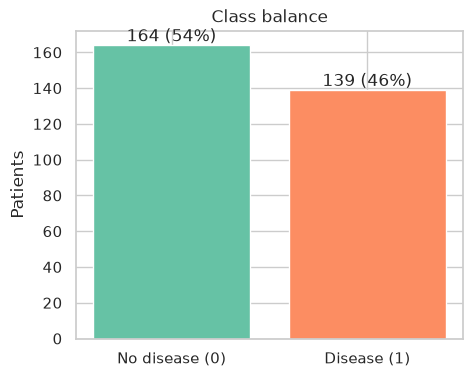

In [4]:
counts = df[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(["No disease (0)", "Disease (1)"], counts.values, color=["#66c2a5", "#fc8d62"])
ax.bar_label(bars, labels=[f"{c} ({c / len(df):.0%})" for c in counts.values])
ax.set_title("Class balance")
ax.set_ylabel("Patients")
save(fig, "01_class_balance")
plt.show()

## 3. Numeric features: sick vs healthy

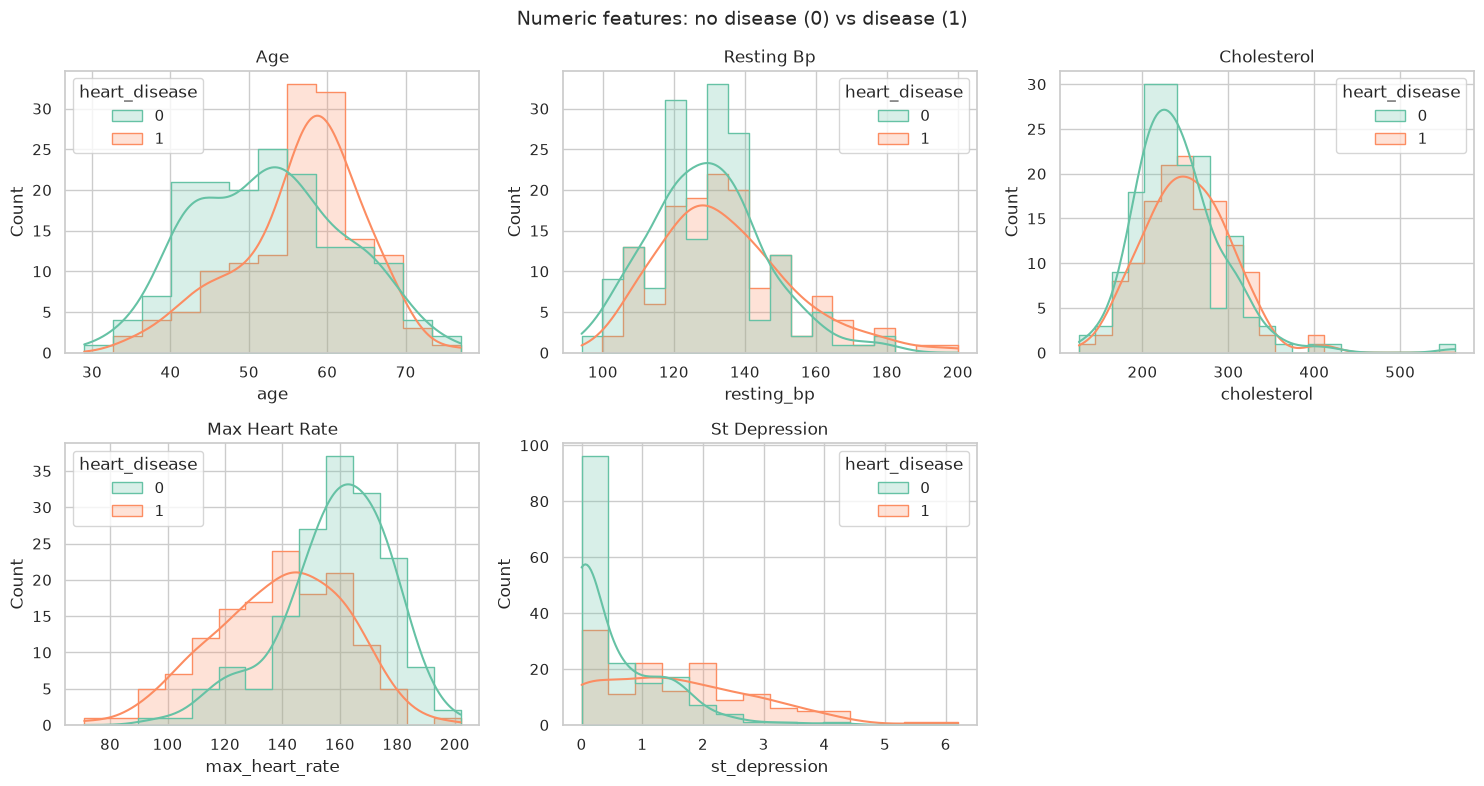

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, NUMERIC):
    sns.histplot(data=df, x=col, hue=TARGET, kde=True, element="step", ax=ax)
    ax.set_title(col.replace("_", " ").title())
axes.flat[-1].axis("off")  # 5 charts in 6 slots: hide the empty one
fig.suptitle("Numeric features: no disease (0) vs disease (1)", fontsize=14)
fig.tight_layout()
save(fig, "02_numeric_histograms")
plt.show()

## 4. Disease rate within each category

`n=` shows group size: a high rate in a tiny group is not reliable.

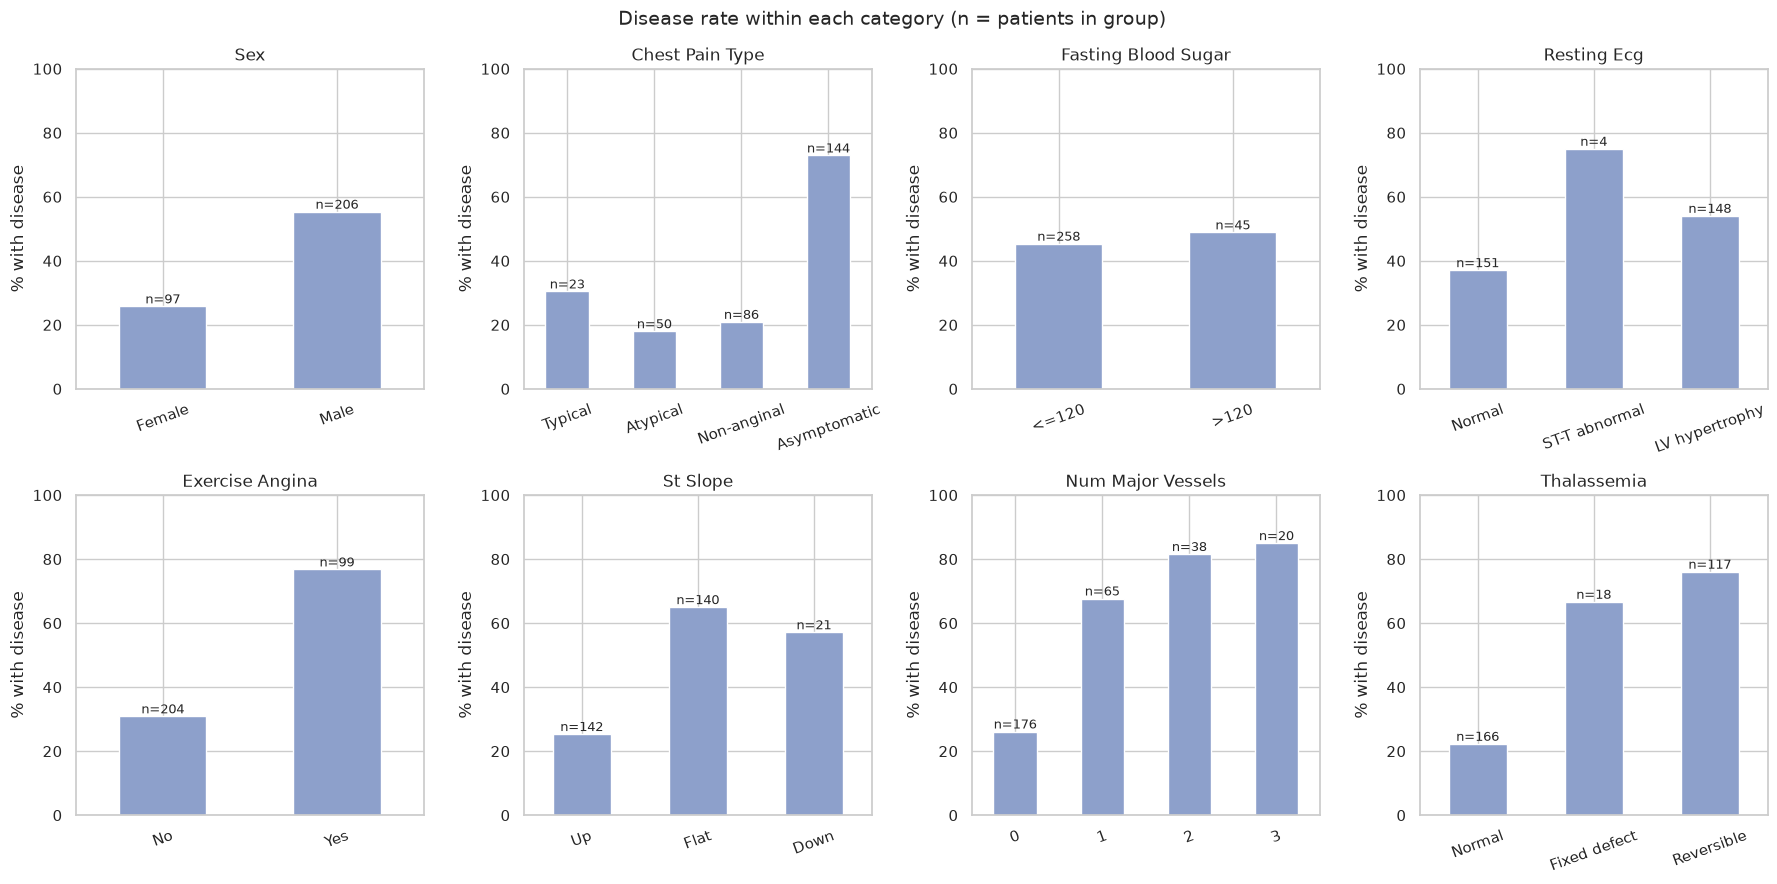

In [6]:
LABELS = {
    "sex": {0: "Female", 1: "Male"},
    "chest_pain_type": {1: "Typical", 2: "Atypical", 3: "Non-anginal", 4: "Asymptomatic"},
    "fasting_blood_sugar": {0: "<=120", 1: ">120"},
    "resting_ecg": {0: "Normal", 1: "ST-T abnormal", 2: "LV hypertrophy"},
    "exercise_angina": {0: "No", 1: "Yes"},
    "st_slope": {1: "Up", 2: "Flat", 3: "Down"},
    "num_major_vessels": {0: "0", 1: "1", 2: "2", 3: "3"},
    "thalassemia": {3: "Normal", 6: "Fixed defect", 7: "Reversible"},
}

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, col in zip(axes.flat, CATEGORICAL):
    rate = df.groupby(col)[TARGET].mean().mul(100)
    sizes = df[col].value_counts().sort_index()
    rate.index = [LABELS[col].get(int(v), v) for v in rate.index]
    rate.plot(kind="bar", ax=ax, color="#8da0cb")
    ax.bar_label(ax.containers[0], labels=[f"n={n}" for n in sizes.values], fontsize=9)
    ax.set_title(col.replace("_", " ").title())
    ax.set_xlabel("")
    ax.set_ylabel("% with disease")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=20)
fig.suptitle("Disease rate within each category (n = patients in group)", fontsize=14)
fig.tight_layout()
save(fig, "03_categorical_disease_rate")
plt.show()

## 5. Correlation heatmap

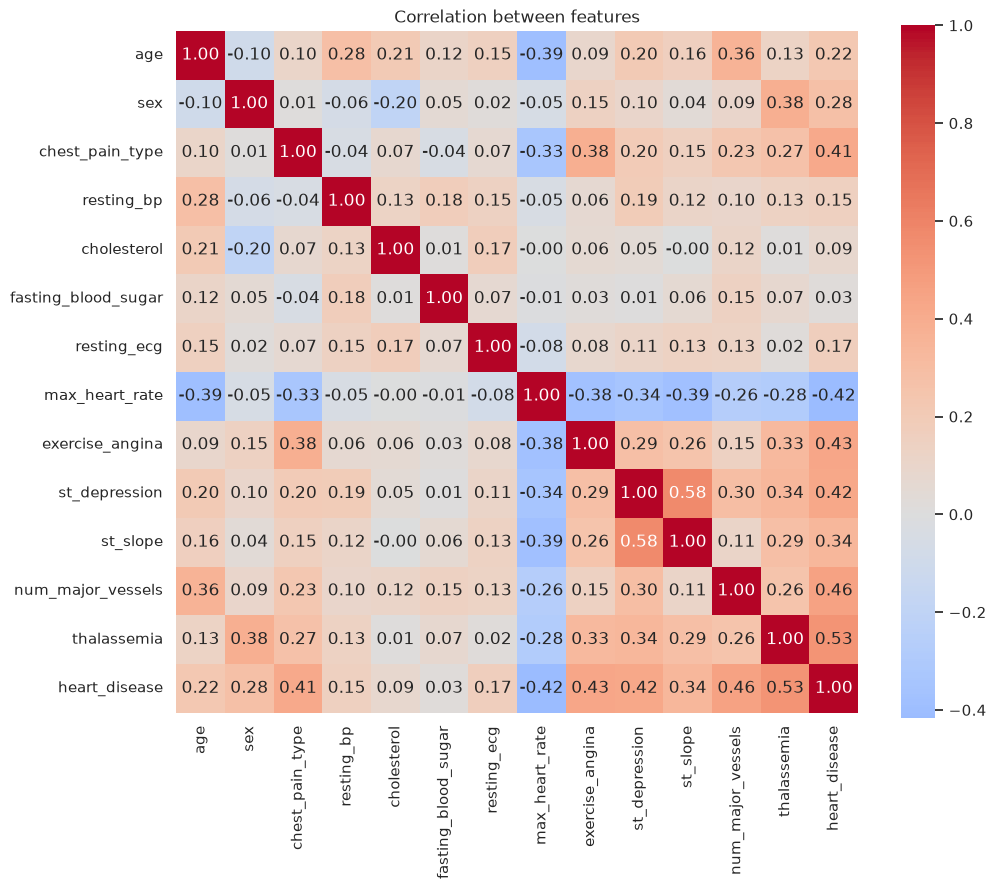

thalassemia            0.53
num_major_vessels      0.46
exercise_angina        0.43
st_depression          0.42
max_heart_rate        -0.42
chest_pain_type        0.41
st_slope               0.34
sex                    0.28
age                    0.22
resting_ecg            0.17
resting_bp             0.15
cholesterol            0.09
fasting_blood_sugar    0.03
Name: heart_disease, dtype: float64

In [7]:
corr = df.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, ax=ax)
ax.set_title("Correlation between features")
save(fig, "04_correlation_heatmap")
plt.show()

corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(2)

## 6. Key findings

*(Write these in your own words after looking at the charts above.)*

- **Balance:**
- **Numeric features (age, max heart rate, ST depression, cholesterol, resting BP):**
- **Categories (chest pain type, vessels, exercise angina, thalassemia):**
- **Top 3 features linked to the target:**
- **Limitation:**